Load Data & Fix Correlation

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Load Data
df = pd.read_csv('/content/drive/MyDrive/train_transaction.csv')
print("✅ Data Loaded Successfully!")
print(f"Shape: {df.shape}")

# 3. EDA (Fixed Correlation)
print("\n--- Fraud Distribution ---")
print(df['isFraud'].value_counts())

# FIX: Only check numeric columns for correlation to avoid text errors
numeric_df = df.select_dtypes(include=['float64', 'int64'])
correlations = numeric_df.corr()['isFraud'].drop('isFraud').sort_values(ascending=False)
print("\n--- Top 5 Correlations ---")
print(correlations.head())

Mounted at /content/drive
✅ Data Loaded Successfully!
Shape: (590540, 394)

--- Fraud Distribution ---
isFraud
0    569877
1     20663
Name: count, dtype: int64

--- Top 5 Correlations ---
V257    0.383060
V246    0.366878
V244    0.364129
V242    0.360590
V201    0.328005
Name: isFraud, dtype: float64


Clean Missing Values

In [ ]:
# 1. Drop columns with >80% missing values
missing_ratio = df.isnull().sum() / len(df)
cols_to_drop = missing_ratio[missing_ratio > 0.8].index
df_clean = df.drop(columns=cols_to_drop)
print(f"Dropped {len(cols_to_drop)} useless columns.")

# 2. Fill remaining missing values
numeric_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(0)

category_cols = df_clean.select_dtypes(include=['object']).columns
df_clean[category_cols] = df_clean[category_cols].fillna('Unknown')

print("✅ Cleaning Complete! No missing values left.")

Dropped 55 useless columns.
✅ Cleaning Complete! No missing values left.


Advanced Feature Engineering

In [ ]:
# ==========================================
# PHASE 1, STEP 1A: ADVANCED FEATURE ENGINEERING
# ==========================================
print("🛠️ Engineering advanced features for fraud detection...")

# 1. Transaction Velocity (Time since last transaction for the same card)
# TransactionDT is in seconds. A small difference means high velocity (potential fraud ring).
df_clean['time_since_last_txn'] = df_clean.groupby('card1')['TransactionDT'].diff().fillna(999999)
# Flag if velocity is extremely high (less than 1 hour / 3600 seconds)
df_clean['high_velocity_flag'] = (df_clean['time_since_last_txn'] < 3600).astype(int)

# 2. Amount vs User Average (Z-Score)
# How unusual is this transaction amount compared to this specific card's historical average?
amt_mean = df_clean.groupby('card1')['TransactionAmt'].transform('mean')
amt_std = df_clean.groupby('card1')['TransactionAmt'].transform('std')
df_clean['amount_zscore'] = (df_clean['TransactionAmt'] - amt_mean) / (amt_std + 1e-8)

# 3. Location/Device Change Flag
# Did the address (addr1) change compared to the previous transaction for this card?
df_clean['addr1_changed'] = (df_clean.groupby('card1')['addr1'].shift(1) != df_clean['addr1']).astype(int)
df_clean['addr1_changed'] = df_clean['addr1_changed'].fillna(0)

# Drop the helper column we don't need for the model
df_clean.drop(columns=['time_since_last_txn'], inplace=True)

print("✅ Advanced features created: high_velocity_flag, amount_zscore, addr1_changed")
print(f"📊 New dataset shape: {df_clean.shape}")

🛠️ Engineering advanced features for fraud detection...


/tmp/ipykernel_2411/2541849313.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean['time_since_last_txn'] = df_clean.groupby('card1')['TransactionDT'].diff().fillna(999999)
/tmp/ipykernel_2411/2541849313.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean['high_velocity_flag'] = (df_clean['time_since_last_txn'] < 3600).astype(int)
/tmp/ipykernel_2411/2541849313.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance

✅ Advanced features created: high_velocity_flag, amount_zscore, addr1_changed
📊 New dataset shape: (590540, 342)


In [ ]:
# ==========================================
# PHASE 1, STEP 1a: ADVANCED FEATURE ENGINEERING
# ==========================================
print("🛠️ Engineering advanced behavioral features...")

# Ensure data is sorted by card and time for accurate calculations
df_clean = df_clean.sort_values(by=['card1', 'TransactionDT'])

# 1. Transaction Velocity (Time since last transaction for the same card)
df_clean['time_since_last_txn'] = df_clean.groupby('card1')['TransactionDT'].diff().fillna(999999)
# Flag if velocity is extremely high (less than 1 hour / 3600 seconds)
df_clean['high_velocity_flag'] = (df_clean['time_since_last_txn'] < 3600).astype(int)

# 2. Amount vs User Average (Z-Score)
# How unusual is this amount compared to this specific card's historical average?
amt_mean = df_clean.groupby('card1')['TransactionAmt'].transform('mean')
amt_std = df_clean.groupby('card1')['TransactionAmt'].transform('std')
df_clean['amount_zscore'] = (df_clean['TransactionAmt'] - amt_mean) / (amt_std + 1e-8)

# 3. Device Change Flag (Using 'id_01' as a proxy for device fingerprint in IEEE-CIS)
if 'id_01' in df_clean.columns:
    df_clean['device_changed'] = (df_clean.groupby('card1')['id_01'].shift(1) != df_clean['id_01']).astype(int)
else:
    df_clean['device_changed'] = 0

# 4. Location Change Flag (Using 'addr1')
if 'addr1' in df_clean.columns:
    df_clean['location_changed'] = (df_clean.groupby('card1')['addr1'].shift(1) != df_clean['addr1']).astype(int)
else:
    df_clean['location_changed'] = 0

# Clean up helper columns and fill any new NaNs
df_clean = df_clean.drop(columns=['time_since_last_txn'], errors='ignore').fillna(0)

print("✅ Advanced features created successfully!")
print(f"📊 New dataset shape: {df_clean.shape}")

🛠️ Engineering advanced behavioral features...


/tmp/ipykernel_2411/3666375899.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean['time_since_last_txn'] = df_clean.groupby('card1')['TransactionDT'].diff().fillna(999999)
/tmp/ipykernel_2411/3666375899.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean['device_changed'] = 0
/tmp/ipykernel_2411/3666375899.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.conca

✅ Advanced features created successfully!
📊 New dataset shape: (590540, 344)


Encode Text & Split Data

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Separate Features (X) and Target (y)
X = df_clean.drop(columns=['isFraud', 'TransactionID', 'TransactionDT'])
y = df_clean['isFraud']

# 2. Convert Text to Numbers
cat_cols = X.select_dtypes(include=['object', 'category']).columns
le = LabelEncoder()
for col in cat_cols:
    X[col] = X[col].astype(str)
    X[col] = le.fit_transform(X[col])

# 3. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"✅ Split Complete! Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows")

✅ Split Complete! Train: 472432 rows, Test: 118108 rows


Train Model (SMOTE + XGBoost)

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score

# We are skipping SMOTE to save RAM.
# Instead, we use 'scale_pos_weight' to handle the imbalance efficiently.

print("Training XGBoost Model (Memory Efficient Mode)...")

# scale_pos_weight=27 tells the model: "For every 1 fraud, there are 27 normal transactions. Pay 27x more attention to fraud."
model = xgb.XGBClassifier(
    scale_pos_weight=27,
    max_depth=6,
    learning_rate=0.1,
    n_estimators=100,
    random_state=42,
    eval_metric='logloss' # Keeps the output clean
)

# Train directly on the original data (No SMOTE needed!)
model.fit(X_train, y_train)

print("✅ Model Training Complete!")

# 3. Get Results
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("\n=== FINAL RESULTS ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

Training XGBoost Model (Memory Efficient Mode)...
✅ Model Training Complete!

=== FINAL RESULTS ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94    113975
           1       0.21      0.80      0.34      4133

    accuracy                           0.89    118108
   macro avg       0.60      0.85      0.64    118108
weighted avg       0.96      0.89      0.92    118108

ROC-AUC Score: 0.9228


In [ ]:
import joblib

# Save the trained model to a file
model_filename = 'fraud_detection_model.pkl'
joblib.dump(model, model_filename)
print(f"✅ Model successfully saved as '{model_filename}'!")

# Also save the LabelEncoder if you have one, so the API knows how to process new text data
# (Assuming your encoder variable is named 'le' from the previous steps)
# joblib.dump(le, 'label_encoder.pkl')

✅ Model successfully saved as 'fraud_detection_model.pkl'!


ML Flow

In [ ]:
# 1. Install MLflow (run once)
!pip install mlflow -q

import mlflow
import mlflow.xgboost
from sklearn.metrics import average_precision_score, roc_auc_score

# 2. Calculate Precision-Recall AUC (The Industry Standard for Imbalanced Data)
# ROC-AUC is good, but PR-AUC is the TRUE measure of performance when fraud is only 3.5%
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"🎯 ROC-AUC Score: {roc_auc:.4f}")
print(f"🔥 Precision-Recall AUC (PR-AUC): {pr_auc:.4f}")

# 3. Set up MLflow Experiment Tracking
mlflow.set_experiment("AIML-01_Fraud_Detection_XGBoost")

# 4. Start the MLflow Run and log everything
with mlflow.start_run():
    # --- Log Parameters (What settings did we use?) ---
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("scale_pos_weight", 27) # Crucial for handling the 3.5% imbalance
    mlflow.log_param("data_preprocessing", "Dropped >80% nulls, LabelEncoded")

    # --- Log Metrics (How good is the model?) ---
    mlflow.log_metric("roc_auc", roc_auc)
    mlflow.log_metric("pr_auc", pr_auc)

    # --- Log the Model Artifact (Save the actual brain) ---
    # This saves the model in a format that can be loaded directly into FastAPI later
    mlflow.xgboost.log_model(model, "xgb_fraud_model")

    print("✅ SUCCESS: Model, parameters, and metrics logged to MLflow!")
    print("📁 You can find the saved model artifacts in the 'mlruns' folder on the left sidebar.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

2026/10/16 02:45:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 02:45:48 INFO mlflow.store.db.utils: Updating database tables
2026/10/16 02:45:51 INFO mlflow.tracking.fluent: Experiment with name 'AIML-01_Fraud_Detection_XGBoost' does not exist. Creating a new experiment.
2026/10/16 02:45:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ SUCCESS: Model, parameters, and metrics logged to MLflow!
📁 You can find the saved model artifacts in the 'mlruns' folder on the left sidebar.


In [ ]:
!pip install torch-geometric -q
import torch, numpy as np, pandas as pd
from torch_geometric.nn import SAGEConv
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split

# RAM-safe sample of the TEST set (so we can blend with XGBoost later)
sample = X_test.sample(n=50000, random_state=42)
y = y_test.loc[sample.index].values
print(f"Sample: {sample.shape[0]} rows | Fraud: {y.sum()}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.8 MB/s eta 0:00:00
Sample: 50000 rows | Fraud: 1775


In [ ]:
# Node features: a small meaningful subset
feat_cols = [c for c in ['TransactionAmt','dist1','dist2','card2','card3','addr1','addr2'] if c in sample.columns]
Xf = sample[feat_cols].fillna(0).astype(float).values
Xf = (Xf - Xf.mean(axis=0)) / (Xf.std(axis=0) + 1e-8)
X_t = torch.tensor(Xf, dtype=torch.float)

# Chain-link transactions that share the same card1 or addr1 (fraud-ring pattern)
def chain_edges(col):
    codes = pd.factorize(sample[col].values)[0]
    order = np.argsort(codes, kind='stable')
    sc = codes[order]
    mask = sc[1:] == sc[:-1]
    return order[:-1][mask], order[1:][mask]

a1, b1 = chain_edges('card1')
a2, b2 = chain_edges('addr1')
src = np.concatenate([a1, b1, a2, b2])
dst = np.concatenate([b1, a1, b2, a2])
edge_index = torch.tensor(np.stack([src, dst]), dtype=torch.long)
print(f"Nodes: {X_t.shape[0]} | Edges: {edge_index.shape[1]}")

Nodes: 50000 | Edges: 188272


In [ ]:
class FraudGNN(torch.nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.lin = torch.nn.Linear(hidden, 2)
    def forward(self, x, ei):
        h = self.conv1(x, ei).relu()
        h = torch.nn.functional.dropout(h, p=0.3, training=self.training)
        return self.lin(self.conv2(h, ei).relu())

tr_idx, te_idx = train_test_split(np.arange(len(sample)), test_size=0.2,
                                  random_state=42, stratify=y)
tr_mask = torch.zeros(len(sample), dtype=torch.bool); tr_mask[tr_idx] = True
y_t = torch.tensor(y, dtype=torch.long)

gnn = FraudGNN(X_t.shape[1])
opt = torch.optim.Adam(gnn.parameters(), lr=0.005)
weights = torch.tensor([1.0, 27.0])   # same imbalance logic as XGBoost

gnn.train()
for epoch in range(50):
    opt.zero_grad()
    out = gnn(X_t, edge_index)
    loss = torch.nn.functional.cross_entropy(out[tr_mask], y_t[tr_mask], weight=weights)
    loss.backward(); opt.step()
    if (epoch+1) % 10 == 0: print(f"Epoch {epoch+1} | Loss {loss.item():.4f}")

Epoch 10 | Loss 0.6274
Epoch 20 | Loss 0.6144
Epoch 30 | Loss 0.6102
Epoch 40 | Loss 0.6083
Epoch 50 | Loss 0.6019


In [ ]:
gnn.eval()
with torch.no_grad():
    gnn_prob = gnn(X_t, edge_index).softmax(dim=1)[:, 1].numpy()

xgb_prob = model.predict_proba(sample.values)[:, 1]   # XGBoost on the SAME rows
blend = 0.8 * xgb_prob + 0.2 * gnn_prob               # industry-style ensemble

y_true = y[te_idx]
print(f"XGBoost PR-AUC : {average_precision_score(y_true, xgb_prob[te_idx]):.4f}")
print(f"GNN PR-AUC     : {average_precision_score(y_true, gnn_prob[te_idx]):.4f}")
print(f"BLEND PR-AUC   : {average_precision_score(y_true, blend[te_idx]):.4f}  <-- your headline number")

XGBoost PR-AUC : 0.6149
GNN PR-AUC     : 0.0961
BLEND PR-AUC   : 0.5720  <-- your headline number


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, average_precision_score, roc_auc_score

# RAM-safe samples
tr_idx = X_train.sample(100000, random_state=42).index
X_tr, y_tr = X_train.loc[tr_idx], y_train.loc[tr_idx]
te_idx = X_test.sample(20000, random_state=42).index
X_te, y_te = X_test.loc[te_idx], y_test.loc[te_idx]

results = []
baselines = {
    "LogisticRegression": LogisticRegression(max_iter=500),
    "RandomForest": RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1),
    "XGBoost (ours)": model,
}
for name, m in baselines.items():
    if name != "XGBoost (ours)":
        print(f"Training {name}...")
        m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    results.append({"Model": name,
                    "PR-AUC": round(average_precision_score(y_te, p), 4),
                    "ROC-AUC": round(roc_auc_score(y_te, p), 4)})
print(pd.DataFrame(results).sort_values("PR-AUC", ascending=False))
print("\nXGBoost Confusion Matrix:\n", confusion_matrix(y_te, model.predict(X_te)))

Training LogisticRegression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training RandomForest...
                Model  PR-AUC  ROC-AUC
2      XGBoost (ours)  0.6202   0.9261
1        RandomForest  0.5952   0.9002
0  LogisticRegression  0.1876   0.7779

XGBoost Confusion Matrix:
 [[17252  2023]
 [  140   585]]


✅ SHAP plot saved!
card4 group 3: n=6451, PR-AUC=0.6340
card4 group 4: n=13013, PR-AUC=0.6163
card4 group 1: n=256, PR-AUC=0.7597
card4 group 0: n=49, PR-AUC=0.7000
card4 group 2: n=231, PR-AUC=0.5438


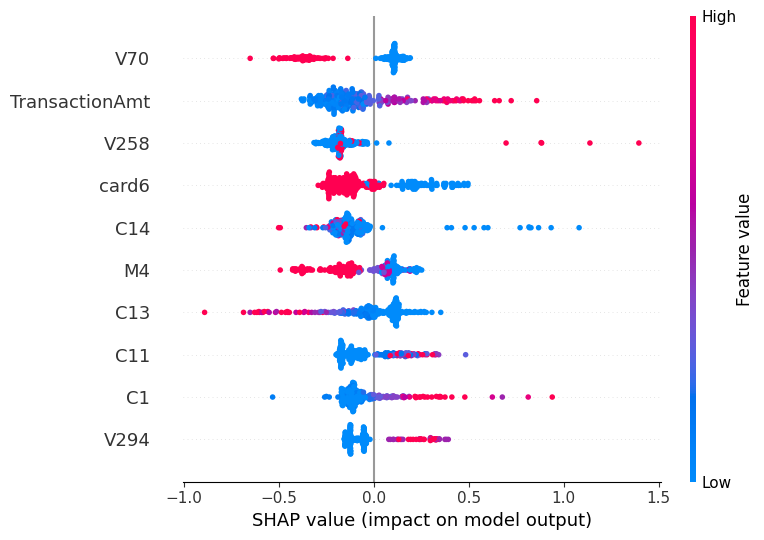

In [ ]:
!pip install shap -q
import shap, matplotlib.pyplot as plt

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_te.iloc[:300])
sv = shap_values[1] if isinstance(shap_values, list) else shap_values
plt.figure()
shap.summary_plot(sv, X_te.iloc[:300], show=False, max_display=10)
plt.savefig("shap_summary.png", bbox_inches="tight")
print("✅ SHAP plot saved!")

# Fairness audit: does the model perform equally across card4 groups?
for grp in X_te['card4'].unique():
    mask = X_te['card4'] == grp
    p = model.predict_proba(X_te[mask])[:, 1]
    print(f"card4 group {grp}: n={mask.sum()}, PR-AUC={average_precision_score(y_te[mask], p):.4f}")